# Análise de RH — Visualização de Dados e Business Intelligence [T3]

**Aluno:** Leonardo Schlichmann  
**Turma:** T3 · Visualização de Dados e Business Intelligence

Análise Exploratória de Dados (EDA) sobre os dados reais extraídos do **FreeSQL**
(esquema HR). Os CSV `query_01.csv` e `query_02.csv` foram gerados pelas consultas
`sql/query_1.sql` e `sql/query_2.sql`.

**Fluxo:** SQL (FreeSQL) → CSV → Python (pandas + matplotlib) → estatísticas e gráficos.

## 0. Dependências
Instala `pandas` e `matplotlib` caso ainda não existam no ambiente (evita `ModuleNotFoundError`).

In [1]:
import sys, subprocess, importlib

def _garantir(pacote, modulo=None):
    modulo = modulo or pacote
    try:
        return importlib.import_module(modulo)
    except ModuleNotFoundError:
        print(f'[setup] instalando {pacote} ...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', pacote])
        return importlib.import_module(modulo)

pd = _garantir('pandas')
matplotlib = _garantir('matplotlib')
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
print('Bibliotecas prontas.')

Bibliotecas prontas.


## 1. Importação dos dados
Leitura dos CSV reais e padronização dos nomes de colunas.

In [2]:
import os
# caminho da pasta data/ (um nivel acima de analysis/)
DATA = os.path.join('..', 'data') if os.path.basename(os.getcwd()) == 'analysis' else 'data'

df1 = pd.read_csv(os.path.join(DATA, 'query_01.csv'))
df2 = pd.read_csv(os.path.join(DATA, 'query_02.csv'))

df1 = df1.rename(columns={'EMPLOYEE_ID':'id_funcionario','FIRST_NAME':'nome','LAST_NAME':'sobrenome',
                          'SALARY':'salario','DEPARTMENT_NAME':'departamento','JOB_TITLE':'cargo'})
df2 = df2.rename(columns={'EMPLOYEE_ID':'id_funcionario','FIRST_NAME':'nome','LAST_NAME':'sobrenome',
                          'SALARY':'salario','DEPARTMENT_NAME':'departamento','JOB_TITLE':'cargo',
                          'CITY':'cidade','COUNTRY_NAME':'pais','REGION_NAME':'regiao'})
print('Query 1:', df1.shape, '| Query 2:', df2.shape)
df1.head()

Query 1: (107, 6) | Query 2: (107, 9)


,id_funcionario,nome,sobrenome,salario,departamento,cargo
0,200,Jennifer,Whalen,4400,Administration,Administration Assistant
1,201,Michael,Martinez,13000,Marketing,Marketing Manager
2,202,Pat,Davis,6000,Marketing,Marketing Representative
3,114,Den,Li,11000,Purchasing,Purchasing Manager
4,115,Alexander,Khoo,3100,Purchasing,Purchasing Clerk


## 2. Visão geral e valores ausentes

In [3]:
print('Tipos de dados (Query 1):')
print(df1.dtypes)
print('\nValores ausentes - Query 1:')
print(df1.isna().sum())
print('\nValores ausentes - Query 2:')
print(df2.isna().sum())
df2.head()

Tipos de dados (Query 1):
id_funcionario    int64
nome                str
sobrenome           str
salario           int64
departamento        str
cargo               str
dtype: object

Valores ausentes - Query 1:
id_funcionario    0
nome              0
sobrenome         0
salario           0
departamento      1
cargo             0
dtype: int64

Valores ausentes - Query 2:
id_funcionario    0
nome              0
sobrenome         0
salario           0
departamento      1
cargo             0
cidade            1
pais              1
regiao            1
dtype: int64


,id_funcionario,nome,sobrenome,salario,departamento,cargo,cidade,pais,regiao
0,103,Alexander,James,9000,IT,Programmer,Southlake,United States of America,Americas
1,104,Bruce,Miller,6000,IT,Programmer,Southlake,United States of America,Americas
2,105,David,Williams,4800,IT,Programmer,Southlake,United States of America,Americas
3,106,Valli,Jackson,4800,IT,Programmer,Southlake,United States of America,Americas
4,107,Diana,Nguyen,4200,IT,Programmer,Southlake,United States of America,Americas


## 3. Estatísticas descritivas do salário
Média, mediana, mínimo, máximo, desvio-padrão e quartis.

In [4]:
sal = df1['salario']
resumo = {
    'contagem': sal.count(), 'media': sal.mean(), 'mediana': sal.median(),
    'desvio_padrao': sal.std(), 'minimo': sal.min(), 'maximo': sal.max(),
    'Q1': sal.quantile(0.25), 'Q3': sal.quantile(0.75),
}
for k, v in resumo.items():
    print(f'{k:<14}: {v:,.2f}')
print('\ndescribe():')
sal.describe()

contagem      : 107.00
media         : 6,461.83
mediana       : 6,200.00
desvio_padrao : 3,909.58
minimo        : 2,100.00
maximo        : 24,000.00
Q1            : 3,100.00
Q3            : 8,900.00

describe():


count      107.00
mean     6,461.83
std      3,909.58
min      2,100.00
25%      3,100.00
50%      6,200.00
75%      8,900.00
max     24,000.00
Name: salario, dtype: float64

## 4. Agrupamentos

In [5]:
por_depto = (df1.dropna(subset=['departamento'])
             .groupby('departamento')['salario']
             .agg(['count','mean','median','min','max'])
             .sort_values('mean', ascending=False))
por_depto.round(2)

,count,mean,median,min,max
departamento,,,,,
Executive,3,"19,333.33","17,000.00",17000,24000
Accounting,2,"10,154.00","10,154.00",8300,12008
Public Relations,1,"10,000.00","10,000.00",10000,10000
Marketing,2,"9,500.00","9,500.00",6000,13000
Sales,34,"8,955.88","8,900.00",6100,14000
Finance,6,"8,601.33","8,000.00",6900,12008
Human Resources,1,"6,500.00","6,500.00",6500,6500
IT,5,"5,760.00","4,800.00",4200,9000
Administration,1,"4,400.00","4,400.00",4400,4400


In [6]:
por_cargo = (df1.groupby('cargo')['salario']
             .agg(['count','mean']).sort_values('mean', ascending=False))
por_cargo.head(10).round(2)

,count,mean
cargo,,
President,1,"24,000.00"
Administration Vice President,2,"17,000.00"
Marketing Manager,1,"13,000.00"
Sales Manager,5,"12,200.00"
Finance Manager,1,"12,008.00"
Accounting Manager,1,"12,008.00"
Purchasing Manager,1,"11,000.00"
Public Relations Representative,1,"10,000.00"
Sales Representative,30,"8,350.00"


In [7]:
por_regiao = (df2.dropna(subset=['regiao'])
              .groupby('regiao')['salario']
              .agg(['count','mean','median','min','max'])
              .sort_values('mean', ascending=False))
print(por_regiao.round(2))
print('\nFuncionarios por pais:')
df2['pais'].value_counts(dropna=False)

          count     mean   median   min    max
regiao                                        
Europe       36 8,916.67 8,900.00  6100  14000
Americas     70 5,191.66 3,300.00  2100  24000

Funcionarios por pais:


pais
United States of America                                68
United Kingdom of Great Britain and Northern Ireland    35
Canada                                                   2
Germany                                                  1
NaN                                                      1
Name: count, dtype: int64

## 5. Visualizações
### 5.1 Histograma da distribuição salarial

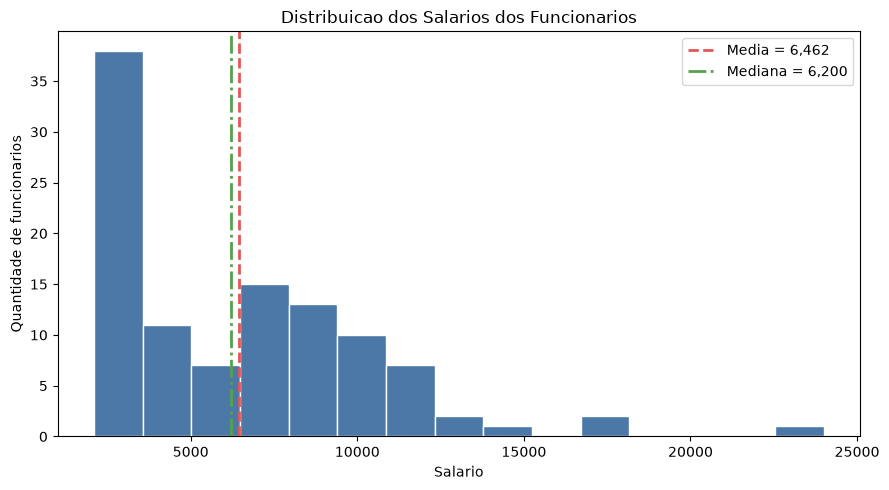

In [8]:
plt.figure(figsize=(9,5))
plt.hist(sal, bins=15, color='#4C78A8', edgecolor='white')
plt.axvline(sal.mean(), color='#E45756', linestyle='--', linewidth=2, label=f'Media = {sal.mean():,.0f}')
plt.axvline(sal.median(), color='#54A24B', linestyle='-.', linewidth=2, label=f'Mediana = {sal.median():,.0f}')
plt.title('Distribuicao dos Salarios dos Funcionarios')
plt.xlabel('Salario'); plt.ylabel('Quantidade de funcionarios'); plt.legend()
plt.tight_layout(); plt.show()

### 5.2 Boxplot de salário por departamento (principais)

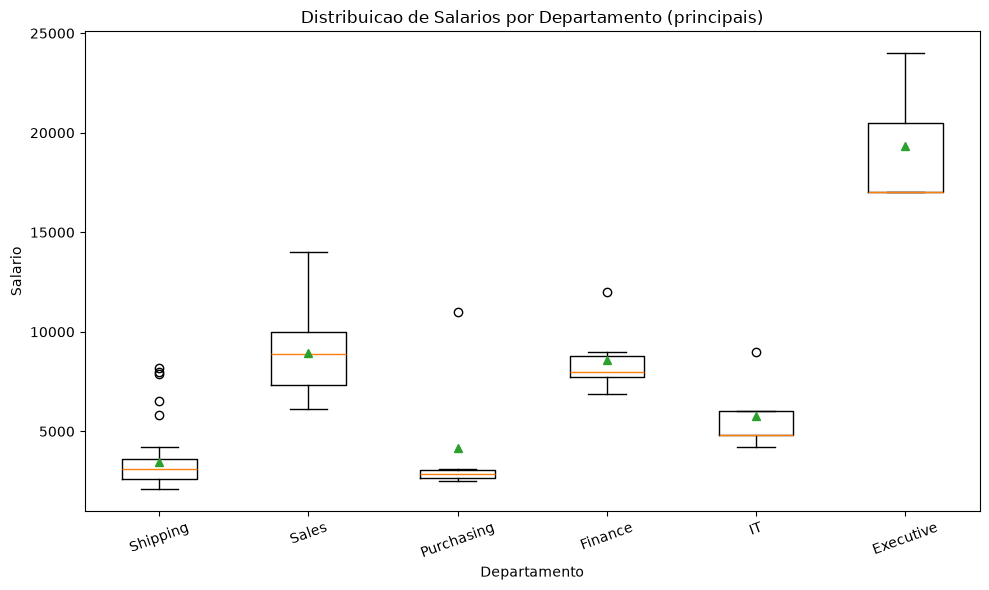

In [9]:
df1_dep = df1.dropna(subset=['departamento'])
top = df1_dep['departamento'].value_counts().head(6).index.tolist()
dados = [df1_dep.loc[df1_dep['departamento']==d, 'salario'] for d in top]
plt.figure(figsize=(10,6))
try:
    plt.boxplot(dados, tick_labels=top, showmeans=True)
except TypeError:
    plt.boxplot(dados, labels=top, showmeans=True)
plt.title('Distribuicao de Salarios por Departamento (principais)')
plt.xlabel('Departamento'); plt.ylabel('Salario'); plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

### 5.3 Salário médio por região

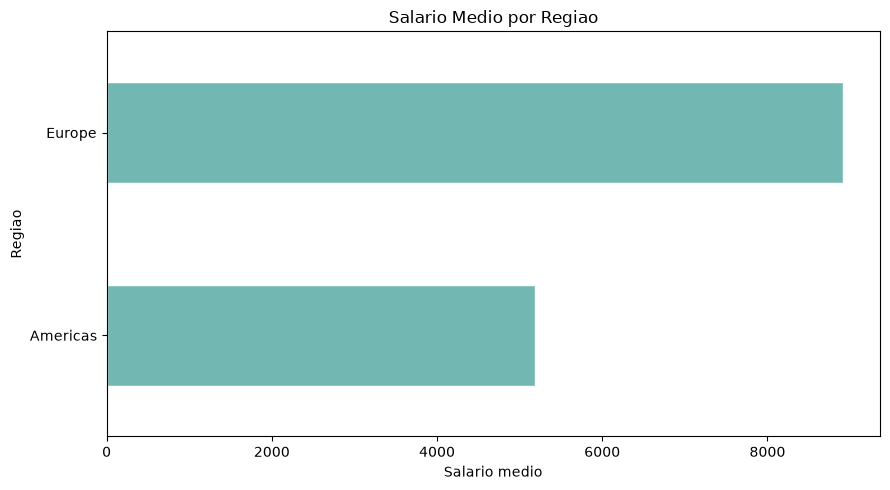

In [10]:
plt.figure(figsize=(9,5))
por_regiao['mean'].sort_values().plot(kind='barh', color='#72B7B2', edgecolor='white')
plt.title('Salario Medio por Regiao'); plt.xlabel('Salario medio'); plt.ylabel('Regiao')
plt.tight_layout(); plt.show()

## 6. Principais insights

- **Média (~6.462) > Mediana (~6.200):** distribuição **assimétrica à direita** —
  poucos salários muito altos (presidência e VPs) puxam a média para cima.
- **Departamento:** *Executive* tem o maior salário médio (~19.333) e *Shipping*
  o menor (~3.476). *Shipping* (45) e *Sales* (34) concentram a maioria das pessoas.
- **Região:** *Europe* (~8.917) acima de *Americas* (~5.192), mas a maioria dos
  funcionários está em *Americas*. A diferença reflete a **composição de cargos**
  por região, não necessariamente a geografia em si.
- **Limitação:** retrato estático; não considera comissões, tempo de casa nem
  custo de vida. 1 funcionário sem departamento/região foi desconsiderado nos
  agrupamentos geográficos.

In [11]:
print('Maior media (depto):', por_depto.index[0], round(por_depto.iloc[0]["mean"]))
print('Menor media (depto):', por_depto.index[-1], round(por_depto.iloc[-1]["mean"]))
print('Media geral:', round(sal.mean()), '| Mediana:', round(sal.median()))
print('Regiao com mais funcionarios:', df2["regiao"].value_counts().index[0])
print('Analise concluida.')

Maior media (depto): Executive 19333
Menor media (depto): Shipping 3476
Media geral: 6462 | Mediana: 6200
Regiao com mais funcionarios: Americas
Analise concluida.
